In [1]:
import mgrs
import numpy as np
from shapely.geometry import Polygon, Point, box
from shapely.ops import unary_union

ModuleNotFoundError: No module named 'mgrs'

In [ ]:
# -------------------------------------------------------------------
# 1. Define Alaska bounding polygon (approximate, WGS84 lon/lat)
#    Excludes the SE Alaska panhandle (east of ~141°W, below ~60°N)
# -------------------------------------------------------------------

# Rough Alaska mainland + western islands polygon (excluding SE panhandle and Aleutians)
alaska_coords = [
    # --- Revised lower-left: tightened to Kodiak / Bristol Bay rim ---
    (-152.5, 57.5),  # Near Kodiak Island
    (-154.5, 57.5),  # Shelikof Strait / upper Alaska Peninsula
    (-157.0, 58.0),  # Alaska Peninsula base / lower Bristol Bay
    (-160.5, 58.5),  # Western Bristol Bay mouth
    (-163.0, 58.8),  # Just beyond Bristol Bay to the west
    (-165.0, 60.0),  # Swing north past Nushagak area
    (-165.5, 63.5),  # Yukon Delta / interior west coast
    (-168.5, 65.5),
    (-166.0, 68.5),
    (-162.0, 70.5),
    (-156.0, 71.5),
    (-141.0, 71.5),  # North along Canadian border
    (-141.0, 59.5),  # SE panhandle cutoff
    (-148.0, 59.5),
    (-151.0, 59.0),
    (-152.5, 57.5),  # Close back to Kodiak
]


alaska_polygon = Polygon(alaska_coords)

# Optional: validate
print(f"Polygon valid: {alaska_polygon.is_valid}")
print(f"Bounds: {alaska_polygon.bounds}")  # (minx, miny, maxx, maxy)

Polygon valid: True
Bounds: (-168.5, 57.5, -141.0, 71.5)


In [6]:
# -------------------------------------------------------------------
# 2. Generate candidate lat/lon points at ~0.5° spacing and convert
#    to MGRS, then check intersection
# -------------------------------------------------------------------

m = mgrs.MGRS()

# Bounding box of our polygon
min_lon, min_lat, max_lon, max_lat = alaska_polygon.bounds

step = 0.5  # degrees — adjust for finer/coarser resolution
mgrs_tiles = set()

lats = np.arange(min_lat, max_lat, step)
lons = np.arange(min_lon, max_lon, step)

for lat in lats:
    for lon in lons:
        point = Point(lon, lat)
        if alaska_polygon.contains(point):
            try:
                # Convert to MGRS at 100km precision (resolution=0)
                tile = m.toMGRS(lat, lon, MGRSPrecision=0)
                mgrs_tiles.add(tile)
            except Exception as e:
                pass  # Some edge points near poles/dateline may fail

print(f"\nFound {len(mgrs_tiles)} unique MGRS 100km tiles:")
for tile in sorted(mgrs_tiles):
    print(tile)


Found 240 unique MGRS 100km tiles:
03VWF
03VWG
03VWH
03VWJ
03VWK
03VWL
03VXF
03VXG
03VXH
03VXJ
03VXK
03VXL
03WUN
03WUP
03WVL
03WVM
03WVN
03WVP
03WVQ
03WVR
03WWL
03WWM
03WWN
03WWP
03WWQ
03WWR
03WWS
03WWT
03WXL
03WXM
03WXN
03WXP
03WXQ
03WXR
03WXS
04VCL
04VCM
04VCN
04VCP
04VCQ
04VCR
04VDK
04VDL
04VDM
04VDN
04VDP
04VDQ
04VDR
04VEK
04VEL
04VEM
04VEN
04VEP
04VEQ
04VER
04VFK
04VFL
04VFM
04VFN
04VFP
04VFQ
04VFR
04WCA
04WCB
04WCC
04WCR
04WCS
04WCT
04WCU
04WCV
04WDA
04WDB
04WDC
04WDD
04WDR
04WDS
04WDT
04WDU
04WDV
04WEA
04WEB
04WEC
04WED
04WER
04WES
04WET
04WEU
04WEV
04WFA
04WFB
04WFR
04WFS
04WFT
04WFU
04WFV
05VLE
05VLF
05VLG
05VLH
05VLJ
05VLK
05VLL
05VME
05VMF
05VMG
05VMH
05VMJ
05VMK
05VML
05VNE
05VNF
05VNG
05VNH
05VNJ
05VNK
05VNL
05VPF
05VPG
05VPH
05VPJ
05VPK
05VPL
05WLL
05WLM
05WLN
05WLP
05WLQ
05WLR
05WLS
05WLT
05WLU
05WML
05WMM
05WMN
05WMP
05WMQ
05WMR
05WMS
05WMT
05WMU
05WNL
05WNM
05WNN
05WNP
05WNQ
05WNR
05WNS
05WNT
05WNU
05WPL
05WPM
05WPN
05WPP
05WPQ
05WPR
05WPS
06VUL
06VUM
06VUN
06VUP
06VU

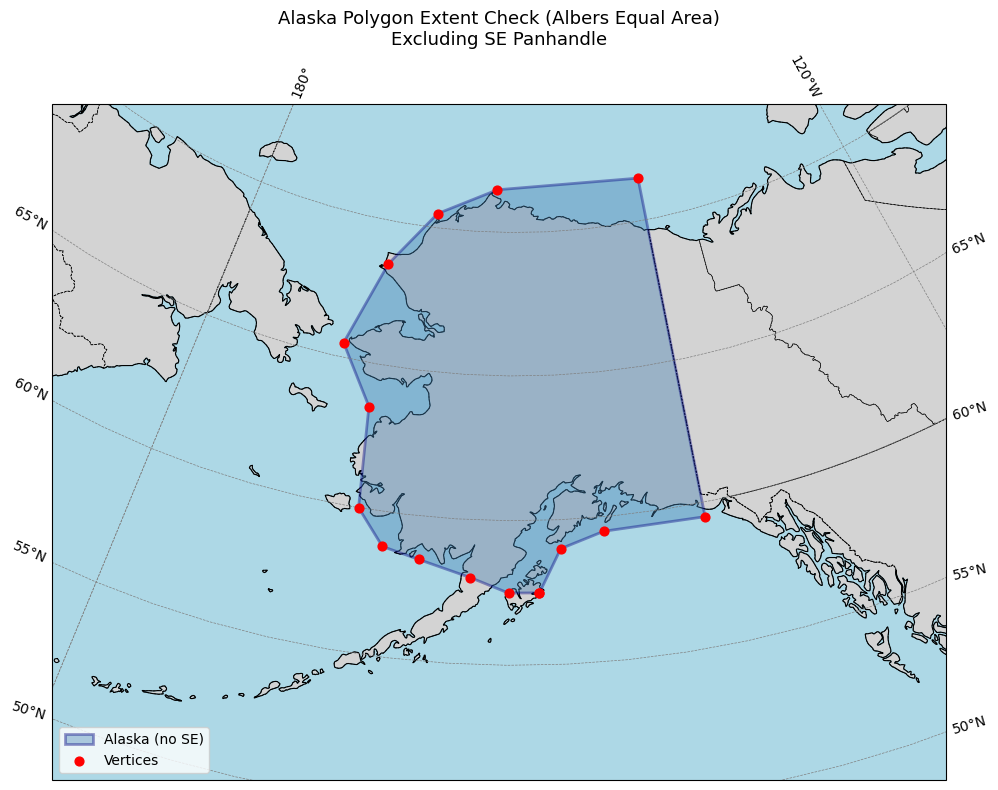

In [4]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Polygon

alaska_coords = [
    # --- Revised lower-left: tightened to Kodiak / Bristol Bay rim ---
    (-152.5, 57.5),  # Near Kodiak Island
    (-154.5, 57.5),  # Shelikof Strait / upper Alaska Peninsula
    (-157.0, 58.0),  # Alaska Peninsula base / lower Bristol Bay
    (-160.5, 58.5),  # Western Bristol Bay mouth
    (-163.0, 58.8),  # Just beyond Bristol Bay to the west
    (-165.0, 60.0),  # Swing north past Nushagak area

    # --- Existing upper/eastern vertices (unchanged) ---
    (-165.5, 63.5),  # Yukon Delta / interior west coast
    (-168.5, 65.5),
    (-166.0, 68.5),
    (-162.0, 70.5),
    (-156.0, 71.5),
    (-141.0, 71.5),  # North along Canadian border
    (-141.0, 59.5),  # SE panhandle cutoff
    (-148.0, 59.5),
    (-151.0, 59.0),
    (-152.5, 57.5),  # Close back to Kodiak
]

alaska_polygon = Polygon(alaska_coords)

# --- Use an Alaska-centered projection ---
proj = ccrs.AlbersEqualArea(
    central_longitude=-154.0,
    central_latitude=63.0,
    standard_parallels=(55.0, 65.0)
)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': proj})

# Set extent: [min_lon, max_lon, min_lat, max_lat]
ax.set_extent([-180, -130, 51, 73], crs=ccrs.PlateCarree())

# Add basemap features
ax.add_feature(cfeature.LAND, color='lightgray', zorder=0)
ax.add_feature(cfeature.OCEAN, color='lightblue', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=1)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.8, zorder=1)
ax.add_feature(cfeature.STATES, linestyle='--', linewidth=0.5, zorder=1)
ax.gridlines(draw_labels=True, linewidth=0.5, linestyle='--', color='gray')

# Plot your polygon
x, y = alaska_polygon.exterior.xy
ax.fill(x, y, transform=ccrs.PlateCarree(),
        alpha=0.4, fc='steelblue', ec='navy', linewidth=2, label='Alaska (no SE)')

# Plot vertices
ax.scatter(x, y, transform=ccrs.PlateCarree(),
           color='red', zorder=5, s=40, label='Vertices')

ax.set_title("Alaska Polygon Extent Check (Albers Equal Area)\nExcluding SE Panhandle", fontsize=13)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

# KML 

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import geopandas as gpd
import pandas as pd
from pathlib import Path
from shapely.geometry import box
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display

# fiona needed for KML driver
import fiona
fiona.drvsupport.supported_drivers["KML"]  = "rw"
fiona.drvsupport.supported_drivers["LIBKML"] = "rw"

In [6]:

# Path to your AOI file (.shp, .geojson, .kml, .kmz)
AOI_PATH = "shapefiles/core_tier1-CCM.kml"

# Path to the Sentinel-2 / HLS MGRS tiling grid
# Download from:
# https://sentiwiki.copernicus.eu/web/s2-products  (search "tiling grid kml")
# or:  https://github.com/justinelliotmeyers/Sentinel-2-Shapefile-Index
S2_GRID_PATH = "shapefiles/S2A_OPER_GIP_TILPAR_MPC__20151209T095117_V20150622T000000_21000101T000000_B00.kml"   # or .shp/.geojson

# Optional: buffer the AOI before querying (metres, in UTM space)
# Set to 0 for no buffer
BUFFER_METRES = 0

# Output CSV of matching tile IDs
OUT_CSV  = "CCM/mgrs_tiles-CCM.csv"

# Map output (set to None to skip saving)
OUT_PNG  = "CCM/mgrs_tile_map-CCM.png"

In [7]:
# =============================================================================
# 02  Helper functions
# =============================================================================

def read_aoi(path: str) -> gpd.GeoDataFrame:
    """
    Read a KML, KMZ, SHP, or GeoJSON into a GeoDataFrame (WGS-84).
    Multiple features are dissolved into a single union geometry.
    """
    path = Path(path)
    ext  = path.suffix.lower()

    if ext in (".kml", ".kmz"):
        layers = fiona.listlayers(str(path))
        print(f"  KML layers found: {layers}")
        gdfs = []
        for layer in layers:
            try:
                gdf = gpd.read_file(str(path), driver="KML", layer=layer)
                if not gdf.empty:
                    gdfs.append(gdf)
            except Exception as e:
                print(f"  [WARN] Could not read layer '{layer}': {e}")

        if not gdfs:
            raise ValueError(f"No readable geometry layers found in {path}")
        gdf = pd.concat(gdfs, ignore_index=True)

    elif ext in (".shp", ".geojson", ".json"):
        gdf = gpd.read_file(str(path))

    else:
        raise ValueError(f"Unsupported file type: {ext}")

    # Reproject to WGS-84 if needed
    if gdf.crs is None:
        print("  [WARN] AOI has no CRS — assuming EPSG:4326")
        gdf = gdf.set_crs("EPSG:4326")
    else:
        gdf = gdf.to_crs("EPSG:4326")

    # Drop empty/null geometries
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()

    if gdf.empty:
        raise ValueError("AOI file contains no valid geometries.")

    print(f"  AOI: {len(gdf)} feature(s) read")
    return gdf


def dissolve_aoi(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    """Union all features into one row."""
    union_geom = gdf.geometry.union_all()          # shapely ≥2.0
    return gpd.GeoDataFrame(geometry=[union_geom], crs=gdf.crs)


def buffer_aoi_metres(gdf: gpd.GeoDataFrame, metres: float) -> gpd.GeoDataFrame:
    """
    Buffer in metres by temporarily projecting to a local equal-area CRS
    (auto UTM), then projecting back to WGS-84.
    """
    if metres <= 0:
        return gdf
    utm_crs = gdf.estimate_utm_crs()
    gdf_utm = gdf.to_crs(utm_crs)
    gdf_utm["geometry"] = gdf_utm.geometry.buffer(metres)
    return gdf_utm.to_crs("EPSG:4326")


def read_s2_grid(path: str) -> gpd.GeoDataFrame:
    """
    Read the Sentinel-2 MGRS tiling grid.
    Handles KML (multi-layer) or SHP/GeoJSON.
    Standardises the tile-name column to 'Name'.
    """
    path = Path(path)
    ext  = path.suffix.lower()

    if ext in (".kml", ".kmz"):
        layers = fiona.listlayers(str(path))
        gdfs = []
        for layer in layers:
            try:
                gdf = gpd.read_file(str(path), driver="KML", layer=layer)
                if not gdf.empty:
                    gdfs.append(gdf)
            except Exception:
                pass
        grid = pd.concat(gdfs, ignore_index=True)

    else:
        grid = gpd.read_file(str(path))

    if grid.crs is None:
        grid = grid.set_crs("EPSG:4326")
    else:
        grid = grid.to_crs("EPSG:4326")

    # Normalise tile-name column
    # Common column names in various grid distributions
    for candidate in ("Name", "name", "TILE", "tile", "Tile",
                      "MGRS_TILE", "mgrs_tile", "TileName"):
        if candidate in grid.columns:
            grid = grid.rename(columns={candidate: "Name"})
            break

    if "Name" not in grid.columns:
        raise ValueError(
            f"Cannot identify tile-name column. "
            f"Available columns: {list(grid.columns)}"
        )

    # Keep only tile name + geometry
    grid = grid[["Name", "geometry"]].copy()
    grid = grid[grid.geometry.notna() & ~grid.geometry.is_empty]

    print(f"  S2 grid: {len(grid):,} tiles loaded")
    return grid


def find_intersecting_tiles(
    aoi: gpd.GeoDataFrame,
    grid: gpd.GeoDataFrame,
) -> gpd.GeoDataFrame:
    """
    Spatial join: return all MGRS tiles that intersect the AOI.
    Uses a bounding-box pre-filter for speed on large grids.
    """
    aoi_union = aoi.geometry.union_all()
    aoi_bbox  = box(*aoi_union.bounds)

    # Coarse filter — bbox intersection
    bbox_mask = grid.geometry.intersects(aoi_bbox)
    candidates = grid[bbox_mask].copy()

    # Precise filter — actual geometry intersection
    hits = candidates[candidates.geometry.intersects(aoi_union)].copy()

    # Add intersection area fraction (what % of tile is covered by AOI)
    hits["intersection_area_deg2"] = hits.geometry.intersection(
        aoi_union
    ).area
    hits["tile_area_deg2"] = hits.geometry.area
    hits["pct_covered"]    = (
        hits["intersection_area_deg2"] / hits["tile_area_deg2"] * 100
    ).round(1)

    hits = hits.sort_values("Name").reset_index(drop=True)
    return hits

In [8]:
print("── Reading AOI ─────────────────────────────────────")
aoi_raw  = read_aoi(AOI_PATH)
aoi      = dissolve_aoi(aoi_raw)

if BUFFER_METRES > 0:
    print(f"  Buffering by {BUFFER_METRES} m ...")
    aoi = buffer_aoi_metres(aoi, BUFFER_METRES)

print(f"\n── Reading S2 MGRS grid ────────────────────────────")
grid = read_s2_grid(S2_GRID_PATH)

print(f"\n── Finding intersecting tiles ──────────────────────")
tiles = find_intersecting_tiles(aoi, grid)

print(f"\n  {len(tiles)} MGRS tile(s) intersect the AOI:")
print()
display(
    tiles[["Name", "pct_covered"]]
    .rename(columns={"Name": "MGRS Tile", "pct_covered": "% Tile Covered"})
)

── Reading AOI ─────────────────────────────────────
  KML layers found: ['ccm_tier1_core_operational']
  AOI: 1 feature(s) read

── Reading S2 MGRS grid ────────────────────────────
  S2 grid: 56,686 tiles loaded

── Finding intersecting tiles ──────────────────────

  4 MGRS tile(s) intersect the AOI:



,MGRS Tile,% Tile Covered
0,12TYP,6.6
1,12TYQ,2.3
2,13TCJ,3.1
3,13TCK,0.6


In [9]:
tiles[["Name", "pct_covered"]].to_csv(OUT_CSV, index=False)
print(f"Tile list saved: {OUT_CSV}")
tile_ids = tiles["Name"].tolist()
print(f"\nTile IDs:\n{tile_ids}")

Tile list saved: CCM/mgrs_tiles-CCM.csv

Tile IDs:
['12TYP', '12TYQ', '13TCJ', '13TCK']


Map saved → CCM/mgrs_tile_map-CCM.png


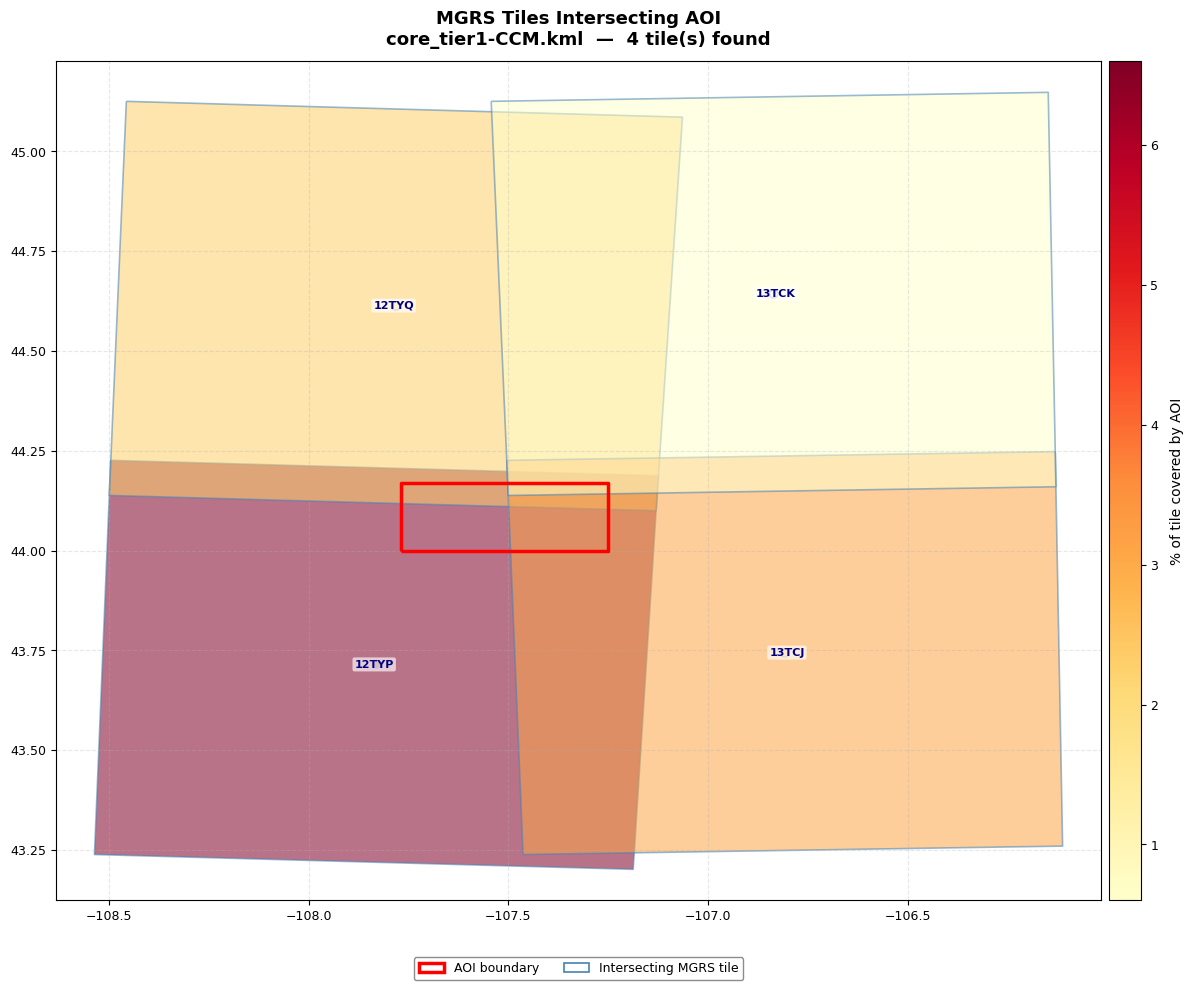

In [18]:
# =============================================================================
# 05  Map  (full layout control — no overlapping)
# =============================================================================
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(14, 12))
ax.set_aspect("equal")

def safe_geom(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
    try:
        gdf["geometry"] = gdf.geometry.make_valid()
    except Exception:
        pass
    valid_bounds = gdf.geometry.apply(
        lambda g: all(np.isfinite(v) for v in g.bounds)
    )
    n_dropped = (~valid_bounds).sum()
    if n_dropped:
        print(f"  [WARN] Dropped {n_dropped} degenerate geometries")
    return gdf[valid_bounds].copy()

# ── Intersecting tiles — NO built-in legend, we'll build the colorbar ─────
tiles_plot = safe_geom(tiles.copy())

vmin = tiles_plot["pct_covered"].min()
vmax = tiles_plot["pct_covered"].max()
cmap_tiles = cm.YlOrRd
norm_tiles  = mcolors.Normalize(vmin=vmin, vmax=vmax)

# Plot without geopandas handling the legend/colorbar at all
tiles_plot.plot(
    ax=ax,
    column="pct_covered",
    cmap=cmap_tiles,
    norm=norm_tiles,
    edgecolor="steelblue",
    linewidth=1.2,
    alpha=0.55,
    legend=False,          # ← we create this manually below
    aspect=None,
)

# ── AOI outline ───────────────────────────────────────────────────────────
aoi.boundary.plot(
    ax=ax,
    linewidth=2.5,
    edgecolor="red",
    aspect=None,
    zorder=6,
)

# ── Tile name labels ───────────────────────────────────────────────────────
for _, row in tiles_plot.iterrows():
    cx, cy = row.geometry.centroid.x, row.geometry.centroid.y
    if not (np.isfinite(cx) and np.isfinite(cy)):
        continue
    ax.text(
        cx, cy,
        row["Name"],
        fontsize=8,
        ha="center", va="center",
        color="navy",
        fontweight="bold",
        zorder=7,
        bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.65),
    )

# ── Extent: full tile footprints + padding ────────────────────────────────
tb   = tiles_plot.geometry.union_all().bounds   # (minx, miny, maxx, maxy)
px   = (tb[2] - tb[0]) * 0.04
py   = (tb[3] - tb[1]) * 0.04
ax.set_xlim(tb[0] - px, tb[2] + px)
ax.set_ylim(tb[1] - py, tb[3] + py)

# ── Colorbar: attached to the RIGHT of the map axes via divider ───────────
# make_axes_locatable keeps it perfectly flush with the map height
divider  = make_axes_locatable(ax)
cax      = divider.append_axes("right", size="3%", pad=0.08)

sm = cm.ScalarMappable(cmap=cmap_tiles, norm=norm_tiles)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("% of tile covered by AOI", fontsize=10, labelpad=8)
cbar.ax.tick_params(labelsize=9)

# ── Legend: below the map, outside axes — uses figure-level placement ──────
legend_handles = [
    mpatches.Patch(
        facecolor="none", edgecolor="red",
        linewidth=2.5, label="AOI boundary"
    ),
    mpatches.Patch(
        facecolor="none", edgecolor="steelblue",
        linewidth=1.2, label="Intersecting MGRS tile"
    ),
]
ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.06),   # below the axes, centred horizontally
    ncol=3,                         # one row of three items
    fontsize=9,
    framealpha=0.9,
    edgecolor="grey",
    title_fontsize=10,
)

# ── Titles / labels ────────────────────────────────────────────────────────
ax.set_title(
    f"MGRS Tiles Intersecting AOI\n"
    f"{Path(AOI_PATH).name}  —  {len(tiles)} tile(s) found",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
# ax.set_xlabel("Longitude", fontsize=10, labelpad=40)  # pad clears the legend
# ax.set_ylabel("Latitude",  fontsize=10)
ax.tick_params(labelsize=9)
ax.grid(True, linestyle="--", alpha=0.3)

# bbox_inches="tight" captures the outside legend in the saved file
plt.savefig(OUT_PNG, dpi=180, bbox_inches="tight")
print(f"Map saved → {OUT_PNG}")
plt.show()

# HLS Continental scale method

In [4]:
import geopandas as gpd
import pandas as pd
from pystac_client import Client

In [5]:
countries = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/10m_cultural/"
    "ne_10m_admin_0_countries.zip"
)

In [40]:
regions = [
    "Canada", "United States of America", "Mexico",
    "Belize", "Guatemala", "Honduras", "El Salvador",
    "Nicaragua", "Costa Rica", "Panama",
    "Cuba", "Jamaica", "Haiti", "Dominican Republic",
    "The Bahamas", "Puerto Rico", "Trinidad and Tobago",
    "Barbados", "Saint Lucia", "Saint Vincent and the Grenadines",
    "Grenada", "Dominica", "Antigua and Barbuda",
    "Saint Kitts and Nevis"
]
out_file_name = "mgrs_tiles_north_central_america.txt"

In [29]:
aoi = countries[countries["ADMIN"].isin(regions)].to_crs("EPSG:4326")
region_geom = aoi.geometry.union_all()

In [25]:
!pwd

/home/jovyan/code/HLS_phenometrics_maap


In [30]:
mgrs_grid = gpd.read_file("/home/jovyan/code/hls-land_tiles/s2_grid.json")

In [31]:
# 3. Ensure both GeoDataFrames share the exact same Coordinate Reference System (CRS)
if mgrs_grid.crs != aoi.crs:
    aoi = aoi.to_crs(mgrs_grid.crs)

In [32]:
# 4. Perform a spatial join to find all MGRS tiles that intersect your AOI regions
# 'inner' ensures we only keep rows that match; 'intersects' captures partial overlaps
matched_tiles_gdf = gpd.sjoin(mgrs_grid, aoi, how="inner", predicate="intersects")

In [33]:
cleaned_tiles_gdf = matched_tiles_gdf[['identifier', 'NAME', 'geometry']].copy()

# 4. Extract your clean unique list of Tile IDs
target_tiles_list = cleaned_tiles_gdf['identifier'].dropna().unique().tolist()

print(f"Found {len(target_tiles_list)} unique matching tiles.")

Found 3282 unique matching tiles.


In [35]:
target_tiles_list[0:5]

['01RCM', '01RGJ', '01RHJ', '01UBS', '01UBT']

In [41]:
with open(out_file_name, 'w') as f:
    for tile in target_tiles_list:
        f.write(f"{tile}\n")